# V93. Прогноз ежедневных регистраций абитуриентов

**Excel → подготовка данных → отдельное обучение потоков → прогноз → CSV.**

Ноутбук воспроизводит V93, для которой пользователь сообщил **Public RMSLE 0,39621**
на общем прогнозе 2024 года. Обучаются три потока: бакалавриат и специалитет,
магистратура, СПО и остальные программы. Общий прогноз — их сумма.

**Как запустить:** поместите рядом с ноутбуком папку `abitur_stage1`, выберите
ядро Python и выполните **Restart Kernel and Run All Cells**. Прогнозы появятся
в `output/v93_notebook`. Все функции, параметры и календарь находятся в ячейках:
другие Python-файлы проекта и готовые прогнозы не требуются.

Считаются **строки регистраций за день**, а не уникальные люди или зачисленные.
Период — 20 июня–31 августа, 73 даты. Проверенный результат относится к общему
прогнозу 2024 года; отдельные потоки отдельно на лидерборде не оценивались.

## 1. Библиотеки

Для воспроизводимости используются версии библиотек V93. Если они ещё не установлены,
раскомментируйте строку установки и выполните её до следующих ячеек.

In [1]:
# %pip install numpy==2.2.6 pandas==2.3.3 catboost==1.2.10 scipy==1.14.1 scikit-learn==1.7.2 openpyxl==3.1.5 matplotlib==3.10.9

In [2]:
from dataclasses import dataclass
from io import StringIO
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from catboost import CatBoostRegressor
from scipy.linalg import solve
from sklearn.preprocessing import SplineTransformer
from IPython.display import display, FileLink

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)

## 2. Настройки запуска

Изменяемые настройки собраны в одной ячейке. `EXPORT_DEGREE` выбирает основной CSV:

| Значение | Содержание |
|---|---|
| `total` | Общая сумма трёх потоков |
| `bachelor` | Бакалавриат и специалитет |
| `master` | Магистратура |
| `background` | СПО и остальные программы |
| `all` | Три потока и общая сумма в одной таблице |

При `SAVE_SEPARATE_FILES = True` дополнительно сохраняются отдельные CSV каждого
потока. Для повторения проверенного прогноза оставьте `TARGET_YEAR = 2024`.

In [3]:
TARGET_YEAR = 2024
INPUT_DIR = Path("abitur_stage1")
OUTPUT_DIR = Path("output/v93_notebook")
EXPORT_DEGREE = "total"
SAVE_SEPARATE_FILES = True

REGISTERED_FILE = INPUT_DIR / "Зарегистрированы (2014-2023).xlsx"
DEGREES = ("bachelor", "master", "background")
DEGREE_NAMES = {
    "bachelor": "Бакалавриат и специалитет",
    "master": "Магистратура",
    "background": "СПО и остальные программы",
}
SLOTS = ("none", "first", "regular", "august", "late")

if EXPORT_DEGREE not in ("total", *DEGREES, "all"):
    raise ValueError("Проверьте EXPORT_DEGREE: total, bachelor, master, background или all")
if not REGISTERED_FILE.is_file():
    raise FileNotFoundError(f"Не найден Excel: {REGISTERED_FILE.resolve()}")

## 3. Чтение исходного Excel

Для V93 нужна выгрузка **«Зарегистрированы (2014–2023)»**, лист `Sheet1`.
Используются дата регистрации `reg_ts` и уровень образования `zayav_type_name`.
Выгрузки «Включены в КС» и «Статусы заявлений» относятся к другим событиям
приёмной кампании и в расчёте V93 не участвуют.

Исходный файл читается напрямую. Промежуточный `registered.csv` не требуется.

In [4]:
raw = pd.read_excel(
    REGISTERED_FILE,
    sheet_name="Sheet1",
    usecols=["reg_ts", "zayav_type_name"],
    engine="openpyxl",
)

if raw[["reg_ts", "zayav_type_name"]].isna().any().any():
    raise ValueError("В исходном Excel пропущены дата регистрации или уровень образования")

print(f"Прочитано регистраций: {len(raw):,}".replace(",", " "))
display(raw.head(5))

Прочитано регистраций: 139 458


,zayav_type_name,reg_ts
0,Бакалавриат и специалитет,2014-06-20 10:52:18
1,Бакалавриат и специалитет,2014-07-02 11:44:13
2,Бакалавриат и специалитет,2014-06-20 10:56:39
3,Бакалавриат и специалитет,2014-07-02 13:56:27
4,Бакалавриат и специалитет,2014-06-20 11:13:36


## 4. Ежедневные количества по потокам

Уровень определяется по названию программы. Дата приводится к началу дня,
после чего строки считаются по парам «дата, поток». Для каждого года строится
полная сетка с 20 июня по 31 августа: день без регистраций получает ноль.
Строки не удаляются как дубликаты по абитуриенту: цель V93 — количество регистраций.

In [5]:
def campaign(year):
    return pd.date_range(f"{year}-06-20", f"{year}-08-31", name="date")

In [6]:
registrations = raw.copy()
registrations["date"] = pd.to_datetime(registrations["reg_ts"], errors="raise").dt.normalize()
registrations["degree"] = np.select(
    [
        registrations["zayav_type_name"].str.startswith(prefix)
        for prefix in ("Бакалавр", "Магистр")
    ],
    DEGREES[:2],
    default="background",
)

source_years = sorted(registrations["date"].dt.year.unique())
if source_years != list(range(source_years[0], source_years[-1] + 1)):
    raise ValueError("В исходных данных отсутствует целый год")

date_grid = pd.DatetimeIndex(
    np.concatenate([campaign(year).values for year in source_years]), name="date"
)
daily_counts = (
    registrations.groupby(["date", "degree"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=date_grid, columns=DEGREES, fill_value=0)
    .astype(float)
)

annual_counts = daily_counts.groupby(daily_counts.index.year).sum()
annual_counts["total"] = annual_counts.sum(axis=1)
display(annual_counts.rename(columns=DEGREE_NAMES | {"total": "Всего регистраций"}))

degree,Бакалавриат и специалитет,Магистратура,СПО и остальные программы,Всего регистраций
date,,,,
2014,12764.0,1579.0,743.0,15086.0
2015,11607.0,3516.0,769.0,15892.0
2016,8542.0,3628.0,833.0,13003.0
2017,9168.0,3245.0,710.0,13123.0
2018,9194.0,2730.0,578.0,12502.0
2019,8637.0,2318.0,637.0,11592.0
2020,11605.0,3135.0,1101.0,15841.0
2021,10694.0,1851.0,949.0,13494.0
2022,10278.0,1847.0,1188.0,13313.0


## 5. Календарь ЕГЭ

Расстояния до дат ЕГЭ используются в модели бакалавриата. Даты из исходной
V93 встроены ниже, поэтому дополнительный входной CSV не нужен. Это даты
экзаменов, а не итоги экзаменов и не количество поступающих.

Таблица поддерживает сезоны 2014–2024. Для другого прогнозного года её нужно
дополнить расписанием соответствующего года. Источник календаря —
[архив ЕГЭ Санкт-Петербурга](https://www.ege.spb.ru/result/index.php?mode=ege2024&wave=1).

In [7]:
EGE_DATES = """year,russian,math,social,english
2014,2014-05-29,2014-06-05,2014-06-11,2014-06-02
2015,2015-05-28,2015-06-04,2015-06-08,2015-06-11
2016,2016-05-30,2016-06-06,2016-06-08,2016-06-14
2017,2017-06-09,2017-06-02,2017-06-05,2017-06-13
2018,2018-06-06,2018-06-01,2018-06-14,2018-06-18
2019,2019-06-03,2019-05-29,2019-06-10,2019-06-05
2020,2020-07-06,2020-07-10,2020-07-16,2020-07-20
2021,2021-06-03,2021-06-07,2021-06-15,2021-06-18
2022,2022-05-30,2022-06-02,2022-06-09,2022-06-14
2023,2023-05-29,2023-06-01,2023-06-08,2023-06-13
2024,2024-05-28,2024-05-31,2024-06-04,2024-06-11"""
exam_source = pd.read_csv(StringIO(EGE_DATES))
exam_calendar = exam_source.set_index("year")[["russian", "math", "social", "english"]].copy()
for subject in exam_calendar:
    exam_calendar[subject] = pd.to_datetime(exam_calendar[subject], errors="raise")

if TARGET_YEAR not in exam_calendar.index:
    raise ValueError(f"Добавьте в календарь ЕГЭ расписание на {TARGET_YEAR} год")
display(
    exam_calendar.loc[[TARGET_YEAR]].rename(
        columns={
            "russian": "Русский язык",
            "math": "Математика",
            "social": "Обществознание",
            "english": "Английский язык",
        }
    )
)

,Русский язык,Математика,Обществознание,Английский язык
year,,,,
2024,2024-05-28,2024-05-31,2024-06-04,2024-06-11


## 6. Параметры V93

Бакалавриат и магистратура используют отдельные CatBoost, остальные программы —
сплайновую регрессию. Числа перенесены из проверенной конфигурации без округления.
Внутри этого ноутбука повторный поиск параметров не выполняется.

| Настройка | Смысл |
|---|---|
| `half_life` | Через сколько лет вес сезона уменьшается вдвое |
| `history_window` | Число последних нормальных сезонов для обучения; 0 — вся история |
| `level_method` | Отдельный уровень сезона: `none`, `mean` или `trend` |
| `level_window` | Число предыдущих сезонов для оценки уровня |
| `coordinates` | Общий календарь или расстояния до собственного срока приёма |
| `align_history` | Определять границы прошлых кампаний по историческим регистрациям |
| `positive_only` | Обучать профиль только на исторических днях с регистрациями |
| `depth`, `iterations`, `learning_rate`, `l2_leaf_reg` | Параметры CatBoost |
| `knots`, `penalty` | Число узлов и регуляризация сплайнов |

Параметры другой семьи модели, например `knots` у CatBoost, не используются.

In [8]:
@dataclass(frozen=True)
class DegreeConfig:
    family: str = "catboost"
    coordinates: str = "event"
    depth: int = 4
    iterations: int = 700
    half_life: float = 3.0
    align_history: bool = True
    level_method: str = "none"
    level_window: int = 3
    exams: bool = False
    knots: int = 9
    penalty: float = 3.0
    history_window: int = 0
    learning_rate: float = 0.035
    l2_leaf_reg: float = 10.0
    positive_only: bool = False
    loss: str = "RMSE"

    def __post_init__(self):
        if self.family not in {"catboost", "spline"} or self.coordinates not in {
            "event",
            "calendar",
        }:
            raise ValueError("Unknown model family or coordinates")
        if self.level_method not in {"none", "mean", "trend"}:
            raise ValueError("Unknown annual level method")
        if (
            min(self.depth, self.iterations, self.half_life, self.penalty) <= 0
            or self.knots < 3
            or self.level_window < 2
        ):
            raise ValueError("Invalid degree configuration")
        if self.history_window not in {0, 3, 5, 7} or self.loss not in {"RMSE", "MAE"}:
            raise ValueError("Invalid history window or training loss")
        if min(self.learning_rate, self.l2_leaf_reg) <= 0:
            raise ValueError("Invalid boosting parameters")

In [9]:
PARAMETERS = {
    "bachelor": {
        "family": "catboost",
        "coordinates": "calendar",
        "depth": 4,
        "iterations": 500,
        "half_life": 2.4219521593767075,
        "align_history": False,
        "level_method": "trend",
        "level_window": 3,
        "exams": True,
        "knots": 9,
        "penalty": 3.0,
        "history_window": 0,
        "learning_rate": 0.04503094501267006,
        "l2_leaf_reg": 2.948883755909228,
        "positive_only": False,
        "loss": "RMSE",
    },
    "master": {
        "family": "catboost",
        "coordinates": "event",
        "depth": 7,
        "iterations": 300,
        "half_life": 3.040427889891538,
        "align_history": True,
        "level_method": "trend",
        "level_window": 3,
        "exams": False,
        "knots": 9,
        "penalty": 3.0,
        "history_window": 5,
        "learning_rate": 0.14172324973151415,
        "l2_leaf_reg": 2.184387671921391,
        "positive_only": False,
        "loss": "MAE",
    },
    "background": {
        "family": "spline",
        "coordinates": "calendar",
        "depth": 4,
        "iterations": 700,
        "half_life": 2.921803597533119,
        "align_history": False,
        "level_method": "none",
        "level_window": 2,
        "exams": False,
        "knots": 5,
        "penalty": 0.032036899931769114,
        "history_window": 0,
        "learning_rate": 0.035,
        "l2_leaf_reg": 10.0,
        "positive_only": True,
        "loss": "RMSE",
    },
}

configs = {degree: DegreeConfig(**values) for degree, values in PARAMETERS.items()}

display(pd.DataFrame(PARAMETERS).rename(columns=DEGREE_NAMES))

,Бакалавриат и специалитет,Магистратура,СПО и остальные программы
family,catboost,catboost,spline
coordinates,calendar,event,calendar
depth,4,7,4
iterations,500,300,700
half_life,2.422,3.0404,2.9218
align_history,False,True,False
level_method,trend,trend,none
level_window,3,3,2
exams,True,False,False
knots,9,9,5


## 7. Календарь приёмной кампании

Субботы разделяются на типы: первая суббота кампании, обычная июльская,
августовская и поздняя августовская. Их рабочий график оценивается по истории.

Ориентиры V93: 25 июля для бакалавриата, 29 июля для магистратуры с переносом
на предыдущую пятницу при выходном, 15 августа для остальных программ.
В историческом 2021 году для бакалавриата используется 29 июля.

In [10]:
def saturday_slots(dates):
    dates = pd.DatetimeIndex(dates)
    position = (dates - pd.to_datetime(dates.year.astype(str) + "-06-20")).days
    return np.select(
        [
            dates.dayofweek != 5,
            position < 7,
            (dates.month == 8) & (dates.day > 21),
            dates.month == 8,
        ],
        ["none", "first", "late", "august"],
        default="regular",
    )


def nominal_deadline(year, degree):
    if degree == "bachelor":
        return pd.Timestamp(f"{year}-07-29" if year == 2021 else f"{year}-07-25")
    if degree == "master":
        date = pd.Timestamp(f"{year}-07-29")
        return date - pd.Timedelta(days=max(date.dayofweek - 4, 0))
    return pd.Timestamp(f"{year}-08-15")

## 8. Исторические сроки и обучающие сезоны

При выравнивании истории ищется последний значимый день, после которого
три дня подряд поток остаётся низким. Это помогает сопоставлять последние
дни приёма в разных годах. Будущие данные в такой поиск не попадают.

Для обучения берутся только годы **до прогнозного**. Аномальный сезон 2020
исключается. Если задано окно истории, каждый поток оставляет нужное ему
число последних нормальных сезонов.

In [11]:
def infer_deadlines(history):
    """Last substantial day followed by three low-count days, in past campaigns."""
    result = {}
    for year in sorted(set(history.index.year)):
        for degree, fraction in (("bachelor", 0.20), ("master", 0.25)):
            series = history.loc[str(year), degree]
            threshold = fraction * series.loc[f"{year}-07-01":f"{year}-07-25"].max()
            if threshold <= 0:
                continue
            for date, count in series.loc[f"{year}-07-20":f"{year}-08-20"].items():
                following = series.loc[
                    date + pd.Timedelta(days=1) : date + pd.Timedelta(days=3)
                ]
                if (
                    count >= threshold
                    and len(following) == 3
                    and (following < threshold).all()
                ):
                    result[int(year), degree] = date
                    break
    return result

In [12]:
def history_before(counts, year):
    history = counts.loc[counts.index.year < year, list(DEGREES)].sort_index().copy()
    years = sorted(history.index.year.unique())
    if len(years) < 2 or years != list(range(years[0], year)):
        raise ValueError("Need contiguous preceding campaigns")
    dates = pd.DatetimeIndex(np.concatenate([campaign(y).values for y in years]), name="date")
    if (
        not history.index.equals(dates)
        or not np.isfinite(history.to_numpy()).all()
        or (history < 0).any().any()
    ):
        raise ValueError("Invalid or incomplete daily counts")
    return history.loc[history.index.year != 2020]

## 9. Признаки одного дня

Признаки описывают день недели, начало кампании, календарное и рабочее
расстояние до срока, последние дни приёма и субботу перед сроком.
Координаты `event` используют собственный срок потока. Координаты `calendar`
дополнительно включают число месяца и положение относительно других сроков.
Для бакалавриата добавляются расстояния до дат ЕГЭ, ограниченные диапазоном
от −14 до 35 дней, как в V93.

In [13]:
def categorical_columns():
    return {
        "weekday": [str(i) for i in range(7)],
        "saturday_slot": list(SLOTS),
        "deadline_weekday": [str(i) for i in range(7)],
    }


def features(dates, degree, deadlines=None, coordinates="event", exams=None):
    dates = pd.DatetimeIndex(dates)
    start = pd.to_datetime(dates.year.astype(str) + "-06-20")
    position = (dates - start).days.to_numpy()
    end = pd.DatetimeIndex(
        [
            (deadlines or {}).get((int(y), degree), nominal_deadline(int(y), degree))
            for y in dates.year
        ]
    )
    distance = (dates - end).days.to_numpy()
    work_distance = np.busday_count(
        end.values.astype("datetime64[D]"),
        dates.values.astype("datetime64[D]"),
        weekmask="1111100",
    )
    result = pd.DataFrame(
        {
            "weekday": dates.dayofweek.astype(str),
            "saturday_slot": saturday_slots(dates),
            "opening_ramp": np.minimum(position, 14),
            "first_day": (position == 0).astype(int),
            "distance": distance,
            "work_distance": work_distance,
            "after_deadline": (distance > 0).astype(int),
            "last_day": (distance == 0).astype(int),
            "last_workday": ((distance <= 0) & (work_distance == 0)).astype(int),
            "last_three_days": ((distance >= -3) & (distance <= 0)).astype(int),
            "last_saturday": (
                (dates.dayofweek == 5) & (distance >= -3) & (distance <= 0)
            ).astype(int),
            "deadline_weekday": end.dayofweek.astype(str),
        },
        index=dates,
    )
    if coordinates == "calendar" or degree == "background":
        result["position"] = position
        result["day"] = dates.day
        result["month"] = dates.month
        for other in ("bachelor", "master"):
            other_end = pd.DatetimeIndex(
                [
                    (deadlines or {}).get((int(y), other), nominal_deadline(int(y), other))
                    for y in dates.year
                ]
            )
            result[f"distance_{other}"] = (dates - other_end).days
    if exams is not None and degree == "bachelor":
        for subject in exams:
            exam_dates = pd.DatetimeIndex(exams.loc[dates.year, subject])
            result[f"since_exam_{subject}"] = np.clip((dates - exam_dates).days, -14, 35)
    return result

In [14]:
display(
    features(
        campaign(TARGET_YEAR)[:5],
        "bachelor",
        coordinates=configs["bachelor"].coordinates,
        exams=exam_calendar if configs["bachelor"].exams else None,
    ).T
)

date,2024-06-20,2024-06-21,2024-06-22,2024-06-23,2024-06-24
weekday,3,4,5,6,0
saturday_slot,none,none,first,none,none
opening_ramp,0,1,2,3,4
first_day,1,0,0,0,0
distance,-35,-34,-33,-32,-31
work_distance,-25,-24,-24,-24,-23
after_deadline,0,0,0,0,0
last_day,0,0,0,0,0
last_workday,0,0,0,0,0
last_three_days,0,0,0,0,0


## 10. Уровень регистраций будущего сезона

Модель работает с $z=\ln(1+n)$, где $n$ — количество регистраций за день.
Уровень сезона — среднее $z$ по будним дням. При `trend` по последним сезонам
оценивается линейный тренд с регуляризацией наклона. Из исторической цели
уровень вычитается, а к прогнозу профиля прибавляется прогноз будущего уровня.

Так отдельно моделируются типичная интенсивность потока и распределение
регистраций внутри сезона. Будущая годовая сумма не задаётся вручную.

In [15]:
def future_level(levels, year, config):
    if config.level_method == "none":
        return 0.0
    earlier = levels.loc[levels.index < year].tail(config.level_window)
    if earlier.empty:
        raise ValueError("Missing historical intensity levels")
    years, values = earlier.index.to_numpy(float), earlier.to_numpy(float)
    weight = np.exp2(-(year - years) / config.half_life)
    center = np.average(years, weights=weight)
    mean = np.average(values, weights=weight)
    if config.level_method == "trend":
        slope = np.sum(weight * (years - center) * (values - mean))
        slope /= np.sum(weight * (years - center) ** 2) + 1.0
        mean += slope * (year - center)
    return max(0.0, float(mean))

## 11. Матрица признаков для модели

CatBoost получает таблицу с категориальными признаками. Для остальных программ
строятся кубические сплайны и взаимодействия со днями недели. Регуляризация
ограничивает величину коэффициентов. Порядок столбцов сохранён из V93.

In [16]:
def make_design(frame, config, fitted_spline=None):
    if config.family == "catboost":
        return frame, None

    coordinates = ["opening_ramp", "distance"]
    if "position" in frame:
        coordinates.append("position")
    values = frame[coordinates].to_numpy()

    if fitted_spline is None:
        knots = [np.linspace(0, 14, config.knots), np.linspace(-60, 50, config.knots)]
        if "position" in frame:
            knots.append(np.linspace(0, 72, config.knots))
        fitted_spline = SplineTransformer(
            knots=np.array(knots).T, degree=3, include_bias=False, extrapolation="linear"
        ).fit(values)

    smooth = fitted_spline.transform(values)
    encoded = frame.copy()
    for column, categories in categorical_columns().items():
        encoded[column] = pd.Categorical(encoded[column], categories=categories)
    encoded = pd.get_dummies(encoded, columns=list(categorical_columns()))

    relative = smooth[:, config.knots + 1 : 2 * (config.knots + 1)]
    weekday = np.column_stack([frame.weekday.eq(str(i)).to_numpy(float) for i in range(1, 6)])
    interaction = (relative[:, :, None] * weekday[:, None, :]).reshape(len(frame), -1)
    matrix = np.column_stack(
        [np.ones((len(frame), 1)), smooth, encoded.to_numpy(float) / 35, interaction]
    )
    return matrix, fitted_spline

## 12. Обучение одного потока

Функция получает только его историческую целевую переменную. Веса сезонов
убывают экспоненциально. Частота нулевых суббот считается по общему
историческому потоку. Воскресенья исключаются из обучения и закрываются
при прогнозе. Для сплайнов СПО дополнительно выбираются положительные дни.

В результате сохраняются обученный регрессор или коэффициенты сплайнов,
уровень будущего сезона и оценки рабочего графика.

In [17]:
def train_degree(counts, degree, year, config, exam_dates):
    history = history_before(counts, year)
    if config.history_window:
        preceding = sorted(set(history.index.year))[-config.history_window :]
        history = history.loc[history.index.year.isin(preceding)].copy()

    training_years = sorted(set(map(int, history.index.year)))
    deadlines = infer_deadlines(history) if config.align_history else {}
    exams = None
    if config.exams and degree == "bachelor":
        if (set(training_years) | {year}) - set(exam_dates.index):
            raise ValueError("В календаре ЕГЭ не хватает нужного года")
        exams = exam_dates.loc[exam_dates.index <= year].copy()

    weights = np.exp2(-(year - history.index.year.to_numpy()) / config.half_life)
    slots = saturday_slots(history.index)
    total = history.sum(axis=1)
    closure_rates = {
        slot: float(np.average(total[slots == slot].eq(0), weights=weights[slots == slot]))
        for slot in ("first", "late", "august", "regular")
    }

    target = np.log1p(history[degree])
    weekdays = history.index.dayofweek < 5
    levels = target[weekdays].groupby(history.index.year[weekdays]).mean()
    level = future_level(levels, year, config)
    if config.level_method != "none":
        target -= history.index.year.map(levels).to_numpy()

    use = history.index.dayofweek != 6
    if config.positive_only:
        use &= history[degree].to_numpy() > 0

    frame = features(history.index, degree, deadlines, config.coordinates, exams)
    design, spline = make_design(frame, config)
    fitted = {
        "degree": degree,
        "config": config,
        "training_years": training_years,
        "exams": exams,
        "level": level,
        "closure_rates": closure_rates,
        "spline": spline,
    }

    if config.family == "catboost":
        regressor = CatBoostRegressor(
            iterations=config.iterations,
            depth=config.depth,
            learning_rate=config.learning_rate,
            l2_leaf_reg=config.l2_leaf_reg,
            loss_function=config.loss,
            cat_features=list(categorical_columns()),
            one_hot_max_size=16,
            random_seed=93001 + DEGREES.index(degree),
            thread_count=1,
            allow_const_label=True,
            verbose=False,
            allow_writing_files=False,
        )
        regressor.fit(design.loc[use], target.loc[use], sample_weight=weights[use])
        fitted["regressor"] = regressor
    else:
        matrix, response, weight = design[use], target.to_numpy()[use], weights[use]
        gram = np.einsum("ni,n,nj->ij", matrix, weight, matrix)
        penalty = np.full(matrix.shape[1], config.penalty)
        penalty[0] = 1e-8
        gram += np.diag(penalty)
        rhs = np.einsum("ni,n,n->i", matrix, weight, response)
        fitted["coefficients"] = solve(gram, rhs, assume_a="pos")

    return fitted

## 13. Обучение трёх отдельных моделей

В этой ячейке выполняется обучение. Таблица показывает, какие сезоны реально
использовал каждый поток и какой уровень был получен из истории.

In [18]:
started = time.perf_counter()
models = {}
training_summary = []

for degree in DEGREES:
    models[degree] = train_degree(
        daily_counts, degree, TARGET_YEAR, configs[degree], exam_calendar
    )
    fitted = models[degree]
    training_summary.append(
        {
            "Поток": DEGREE_NAMES[degree],
            "Модель": configs[degree].family,
            "Сезоны обучения": ", ".join(map(str, fitted["training_years"])),
            "Уровень log1p": fitted["level"],
        }
    )

print(f"Обучение завершено за {time.perf_counter() - started:.2f} с")
display(pd.DataFrame(training_summary).set_index("Поток"))

Обучение завершено за 0.25 с


,Модель,Сезоны обучения,Уровень log1p
Поток,,,
Бакалавриат и специалитет,catboost,"2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022...",3.5428
Магистратура,catboost,"2018, 2019, 2021, 2022, 2023",2.7875
СПО и остальные программы,spline,"2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022...",0.0000


## 14. Прогноз одного потока

Для будущего сезона используются календарные ориентиры, а не наблюдения
будущего года. К прогнозу профиля добавляется уровень сезона. Обратное
преобразование `expm1` возвращает количество регистраций. После этого
применяется оценённый по истории график закрытых дней.

In [19]:
def predict_degree(fitted, year):
    config = fitted["config"]
    degree = fitted["degree"]
    dates = campaign(year)
    frame = features(dates, degree, coordinates=config.coordinates, exams=fitted["exams"])
    design, _ = make_design(frame, config, fitted["spline"])

    if config.family == "catboost":
        profile = fitted["regressor"].predict(design)
    else:
        profile = np.einsum("ni,i->n", design, fitted["coefficients"])

    log_counts = profile + fitted["level"]
    prediction = np.expm1(np.maximum(0.0, log_counts))
    slots = saturday_slots(dates)
    closed = (dates.dayofweek == 6) | np.array(
        [fitted["closure_rates"].get(slot, 0) > 0.5 for slot in slots]
    )
    prediction[closed] = 0.0

    if not np.isfinite(prediction).all():
        raise ValueError("Модель вернула некорректный прогноз")
    return pd.Series(prediction, index=dates, name=degree)

## 15. Общий прогноз и итоги потоков

Общая сумма включает три потока. Поэтому бакалавриат и магистратура вдвоём
не равны общему прогнозу: есть также СПО и остальные программы. Дробные
значения сохраняются как математическое ожидание; округлять их до целых
для конкурсного CSV не нужно.

In [20]:
forecast = pd.concat(
    [predict_degree(models[degree], TARGET_YEAR) for degree in DEGREES], axis=1
)
forecast["forecast"] = forecast.sum(axis=1)
forecast = forecast.reset_index()

display(forecast.head(10).rename(columns=DEGREE_NAMES | {"date": "Дата", "forecast": "Всего"}))
totals = (
    forecast[list(DEGREES) + ["forecast"]]
    .sum()
    .rename(index=DEGREE_NAMES | {"forecast": "Общий прогноз"})
)
display(totals.to_frame("Регистраций за период"))

,Дата,Бакалавриат и специалитет,Магистратура,СПО и остальные программы,Всего
0,2024-06-20,42.7474,0.7926,4.1697,47.7098
1,2024-06-21,43.1887,0.4356,4.8115,48.4357
2,2024-06-22,0.0000,0.0000,0.0000,0.0000
3,2024-06-23,0.0000,0.0000,0.0000,0.0000
4,2024-06-24,119.8849,0.0292,10.4916,130.4056
5,2024-06-25,119.8835,2.0420,8.1877,130.1132
6,2024-06-26,162.1726,2.1570,10.9409,175.2705
7,2024-06-27,215.6587,1.3383,11.6060,228.6030
8,2024-06-28,226.7893,10.5772,12.0396,249.4060
9,2024-06-29,96.3828,11.6254,6.1398,114.1480


,Регистраций за период
Бакалавриат и специалитет,8197.3519
Магистратура,2131.1992
СПО и остальные программы,706.8473
Общий прогноз,11035.3984


## 16. График прогноза

Первый график показывает общую ежедневную динамику, второй — вклад каждого
потока. Провалы до нуля соответствуют закрытым дням календарного правила.

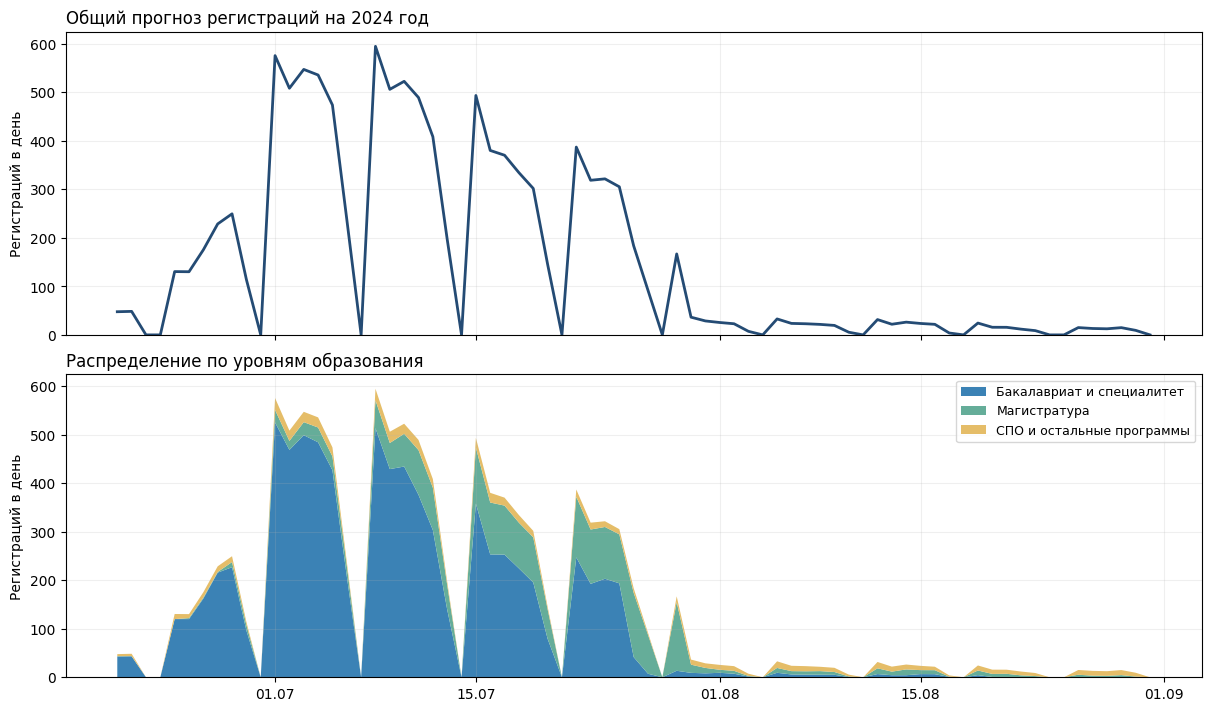

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
axes[0].plot(forecast["date"], forecast["forecast"], color="#244b74", linewidth=2)
axes[0].set_title(f"Общий прогноз регистраций на {TARGET_YEAR} год", loc="left")
axes[1].stackplot(
    forecast["date"],
    *[forecast[degree] for degree in DEGREES],
    labels=[DEGREE_NAMES[degree] for degree in DEGREES],
    colors=["#3b82b5", "#65ad99", "#e5bd68"],
)
axes[1].set_title("Распределение по уровням образования", loc="left")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
for axis in axes:
    axis.set_ylabel("Регистраций в день")
    axis.set_ylim(bottom=0)
    axis.grid(alpha=0.2)
plt.show()

## 17. Сохранение CSV

Основной файл определяется настройкой `EXPORT_DEGREE`. Общий прогноз и
отдельные потоки имеют формат `date,forecast`, как у V93. Файл `components`
содержит все потоки вместе. Сохраняется шесть знаков после запятой.

Выходная папка отдельная: существующий проверенный прогноз проекта
не перезаписывается.

In [22]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
prefix = f"forecast_{TARGET_YEAR}_v93"

suffix = (
    ""
    if EXPORT_DEGREE == "total"
    else f"_{'components' if EXPORT_DEGREE == 'all' else EXPORT_DEGREE}"
)
selected_path = OUTPUT_DIR / f"{prefix}{suffix}.csv"
selected_column = "forecast" if EXPORT_DEGREE == "total" else EXPORT_DEGREE
selected_table = (
    forecast
    if EXPORT_DEGREE == "all"
    else forecast[["date", selected_column]].rename(columns={selected_column: "forecast"})
)
selected_table.to_csv(selected_path, index=False, float_format="%.6f")

written_files = {selected_path}
if SAVE_SEPARATE_FILES:
    for degree in DEGREES:
        path = OUTPUT_DIR / f"{prefix}_{degree}.csv"
        forecast[["date", degree]].rename(columns={degree: "forecast"}).to_csv(
            path, index=False, float_format="%.6f"
        )
        written_files.add(path)
    components_path = OUTPUT_DIR / f"{prefix}_components.csv"
    forecast.to_csv(components_path, index=False, float_format="%.6f")
    written_files.add(components_path)

print(f"Основной CSV: {selected_path}")
for path in sorted(written_files):
    display(FileLink(str(path)))

Основной CSV: output/v93_notebook/forecast_2024_v93.csv


/private/var/folders/j3/3rqsvhyx5cx2hbncr1ntj1f80000gn/T/v93_notebook_excel_t_nqv0jj/output/v93_notebook/forecast_2024_v93.csv

/private/var/folders/j3/3rqsvhyx5cx2hbncr1ntj1f80000gn/T/v93_notebook_excel_t_nqv0jj/output/v93_notebook/forecast_2024_v93_bachelor.csv

/private/var/folders/j3/3rqsvhyx5cx2hbncr1ntj1f80000gn/T/v93_notebook_excel_t_nqv0jj/output/v93_notebook/forecast_2024_v93_background.csv

/private/var/folders/j3/3rqsvhyx5cx2hbncr1ntj1f80000gn/T/v93_notebook_excel_t_nqv0jj/output/v93_notebook/forecast_2024_v93_components.csv

/private/var/folders/j3/3rqsvhyx5cx2hbncr1ntj1f80000gn/T/v93_notebook_excel_t_nqv0jj/output/v93_notebook/forecast_2024_v93_master.csv

## Происхождение настроек

Это перенос фиксированной V93 в ноутбук, а не новый подбор. Гиперпараметры
V93 ранее выбирались по близости к прогнозу V84. Веса моделей в этом ноутбуке
обучаются на исторических регистрациях; файлы V84 и старые прогнозы не читаются.
Источник выбора параметров этим не меняется. Сообщённый пользователем
Public RMSLE 0,39621 относится к исходному общему CSV V93 за 2024 год.